# Lab 2 — What Did the Campaign Deliver?
# Name: Nazar Harbarchuk | Group: KM-41

## Setup

In [1]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/3")

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
commercials = pd.read_parquet(f"{DATA}/commercials.parquet")
rate_card = pd.read_parquet(f"{DATA}/rate_card.parquet")

100%|██████████| 8.00M/8.00M [00:00<00:00, 60.0MB/s]

Extracting files...


## Task 1.1 — Size

In [11]:
print("Spots:", commercials['ad_airing_id'].nunique())
print("Pods:", commercials['pod_id'].nunique())
print("Brands:", commercials['brand'].nunique())
print("Categories:", commercials['category'].nunique())

brand_a = commercials[commercials['brand'] == 'BRAND_A']
print("BRAND_A spots:", len(brand_a))

print("\ntable: BRAND_A spots by network")
print(brand_a['network_code'].value_counts().to_string())

Spots: 167720
Pods: 22359
Brands: 95
Categories: 14
BRAND_A spots: 300

table: BRAND_A spots by network
network_code
FNC      40
HGTV     39
FX       38
HIST     37
BRAVO    33
FOOD     33
ABC      29
CBS      22
NBC      16
FOX      13


## Task 1.2 — Ad load

In [10]:
# Перетворюємо час початку споту у формат datetime та знаходимо конкретну годину
commercials['start_ts'] = pd.to_datetime(commercials['start_ts'])
commercials['clock_hour'] = commercials['start_ts'].dt.floor('h')

# Групуємо за мережею та годиною, сумуємо секунди
hourly_ads = commercials.groupby(['network_code', 'clock_hour'])['length_sec'].sum().reset_index()
hourly_ads['ad_minutes'] = hourly_ads['length_sec'] / 60

# Усереднюємо для кожної мережі по тих годинах, де реклама була (ігноруючи пусті години)
ad_load = hourly_ads.groupby('network_code')['ad_minutes'].mean().round(1).sort_values(ascending=False)

print("table: ad minutes per hour by network")
print(ad_load.to_string())
print("\nHeaviest ad load:", ad_load.index[0])

table: ad minutes per hour by network
network_code
FNC      15.6
BRAVO    13.4
HGTV     13.3
HIST     13.2
FOOD     13.1
FX       12.9
CBS      12.1
ABC      11.8
FOX      11.8
NBC      11.8

Heaviest ad load: FNC


**Answer:** why broadcast networks have hours without national ads.

Major broadcast networks have entire hours without national advertising, as these ad slots are sold entirely by local stations at the local level, or the time is used for paid programming or local news[cite: 2].

## Task 1.3 — Price everything

In [13]:
# 1. Прив'язуємо споти до програм для отримання program_name
comm_prog = commercials.merge(programs[['telecast_id', 'program_name']], on='telecast_id', how='left')

# 2. Розділяємо rate_card на рядки програм та рядки часу
is_time_row = rate_card['program_name'].isna() | (rate_card['program_name'] == '') | (rate_card['program_name'].str.strip() == '')
rc_time = rate_card[is_time_row].copy()
rc_prog = rate_card[~is_time_row].copy()

# 3. Метчинг за назвою програми (спорт тощо)
matched_prog = comm_prog.merge(
    rc_prog[['network_code', 'program_name', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'program_name'],
    how='inner'
)
matched_prog['is_prog_row'] = True

# 4. Відбираємо споти, які не приєдналися за програмою
unmatched_comm = comm_prog[~comm_prog['ad_airing_id'].isin(matched_prog['ad_airing_id'])].copy()

# 5. Метчинг за часом
# Переводимо час ефіру у мовну добу (віднімаємо 6 годин від 06:00)
unmatched_comm['bc_time'] = unmatched_comm['start_ts'] - pd.Timedelta(hours=6)
unmatched_comm['weekday'] = unmatched_comm['bc_time'].dt.weekday # 0 = Monday
unmatched_comm['bc_minutes'] = unmatched_comm['bc_time'].dt.hour * 60 + unmatched_comm['bc_time'].dt.minute

# Функція для перетворення HH:MM на хвилини від 06:00
def time_to_min(t_str):
    h, m = map(int, t_str.split(':'))
    return h * 60 + m - 360

rc_time['start_min'] = rc_time['start_time'].apply(time_to_min)
rc_time['end_min'] = rc_time['end_time'].apply(time_to_min)

# Розгортаємо масив днів тижня
rc_time_exploded = rc_time.explode('weekdays')
rc_time_exploded = rc_time_exploded.dropna(subset=['weekdays']) # Захист від NaN
rc_time_exploded['weekday'] = rc_time_exploded['weekdays'].astype(int)

# Мерджимо за мережею та днем тижня
merged_time = unmatched_comm.merge(
    rc_time_exploded[['network_code', 'weekday', 'start_min', 'end_min', 'daypart', 'cost_30s_usd']],
    on=['network_code', 'weekday'],
    how='left'
)

# Захист від RuntimeWarning: відкидаємо можливі NaN перед порівнянням
merged_time = merged_time.dropna(subset=['start_min'])

# Залишаємо лише ті рядки, де час споту потрапляє в таймслот прайс-листа
matched_time = merged_time[
    (merged_time['bc_minutes'] >= merged_time['start_min']) &
    (merged_time['bc_minutes'] < merged_time['end_min'])
].copy()
matched_time['is_prog_row'] = False
matched_time = matched_time.drop(columns=['bc_time', 'weekday', 'bc_minutes', 'start_min', 'end_min'])

# 6. Об'єднуємо всі оцінені споти
all_priced = pd.concat([matched_prog, matched_time])

# 7. Розраховуємо фінальну вартість з урахуванням довжини ролика (15с = 0.5x, 60с = 2x)
all_priced['cost'] = all_priced['cost_30s_usd'] * (all_priced['length_sec'] / 30)

print("Spots without a price:", len(commercials) - len(all_priced))

# 8. Обчислюємо загальну вартість і частку спортивних програм
all_priced['prog_value'] = np.where(all_priced['is_prog_row'], all_priced['cost'], 0)

network_summary = all_priced.groupby('network_code').agg(
    total_value=('cost', 'sum'),
    prog_value=('prog_value', 'sum')
)

network_summary['total_value_m'] = (network_summary['total_value'] / 1e6).round(0).astype(int)
network_summary['prog_share'] = (network_summary['prog_value'] / network_summary['total_value']).round(3)

print("\ntable: rate-card value by network (USD M) and share from program rows")
print(network_summary[['total_value_m', 'prog_share']].to_string())

Spots without a price: 0

table: rate-card value by network (USD M) and share from program rows
              total_value_m  prog_share
network_code                           
ABC                     709       0.432
BRAVO                    25       0.000
CBS                     819       0.230
FNC                     316       0.000
FOOD                     42       0.000
FOX                     696       0.835
FX                       43       0.000
HGTV                     58       0.000
HIST                     40       0.000
NBC                     724       0.342


## Task 2.1 — Delivery

In [15]:
# 1. Відбираємо валідних осіб (R та L)
dw_rl = daily_weights[daily_weights['resp_type'].isin(['R', 'L'])].copy()
vw_rl = viewings[viewings['resp_type'].isin(['R', 'L'])].copy()
va_rl = viewer_attributes[viewer_attributes['respondent_id'].isin(dw_rl['respondent_id'])].copy()

# 2. Визначаємо цільову аудиторію A18-49
ages = va_rl[va_rl['attr_id'] == 300][['respondent_id', 'value']]
a18_49_ids = set(ages[(ages['value'] >= 18) & (ages['value'] <= 49)]['respondent_id'])

dw_rl['is_a18_49'] = dw_rl['respondent_id'].isin(a18_49_ids)

# 3. Щоденні бази (Universes) для GRPs
daily_univ = dw_rl.groupby('broadcast_date')['weight'].sum().reset_index(name='univ_p2')
daily_univ_a18 = dw_rl[dw_rl['is_a18_49']].groupby('broadcast_date')['weight'].sum().reset_index(name='univ_a18_49')
daily_univ = daily_univ.merge(daily_univ_a18, on='broadcast_date', how='left')

# 4. Місячні бази (Universes) для Reach (за середньомісячною вагою)
person_avg_weight = dw_rl.groupby('respondent_id')['weight'].mean().reset_index()
person_avg_weight['is_a18_49'] = person_avg_weight['respondent_id'].isin(a18_49_ids)
universe_p2 = person_avg_weight['weight'].sum()
universe_a18_49 = person_avg_weight[person_avg_weight['is_a18_49']]['weight'].sum()

# 5. Відбираємо споти BRAND_A та метчимо з переглядами
brand_a_spots = commercials[commercials['brand'] == 'BRAND_A'].copy()
brand_a_spots['broadcast_date'] = (brand_a_spots['start_ts'] - pd.Timedelta(hours=6)).dt.date

merged_vw = vw_rl.merge(brand_a_spots[['ad_airing_id', 'network_code', 'start_ts']], on='network_code', suffixes=('_view', '_spot'))
# Умова контакту: session start < spot start < session end
exposures = merged_vw[(merged_vw['start_ts_spot'] > merged_vw['start_ts_view']) & (merged_vw['start_ts_spot'] < merged_vw['end_ts'])].copy()
exposures['is_a18_49'] = exposures['respondent_id'].isin(a18_49_ids)

# 6. Враження (Impressions) по кожному споту
spot_imps_p2 = exposures.groupby('ad_airing_id')['weight'].sum().reset_index(name='imp_p2')
spot_imps_a18 = exposures[exposures['is_a18_49']].groupby('ad_airing_id')['weight'].sum().reset_index(name='imp_a18_49')
spot_imps = brand_a_spots[['ad_airing_id', 'broadcast_date']].merge(spot_imps_p2, on='ad_airing_id', how='left').fillna(0)
spot_imps = spot_imps.merge(spot_imps_a18, on='ad_airing_id', how='left').fillna(0)

# 7. Розрахунок рейтингів та GRPs
spot_imps = spot_imps.merge(daily_univ, on='broadcast_date', how='left')
spot_imps['rating_p2'] = spot_imps['imp_p2'] / spot_imps['univ_p2'] * 100
spot_imps['rating_a18_49'] = spot_imps['imp_a18_49'] / spot_imps['univ_a18_49'] * 100

imp_p2_tot = spot_imps['imp_p2'].sum() / 1e6
grp_p2 = spot_imps['rating_p2'].sum()
imp_a18_tot = spot_imps['imp_a18_49'].sum() / 1e6
grp_a18 = spot_imps['rating_a18_49'].sum()

# 8. Розрахунок Reach (за середньомісячною вагою тих, хто бачив хоча б 1 спот)
reached_p2 = exposures['respondent_id'].unique()
reach_p2_weight = person_avg_weight[person_avg_weight['respondent_id'].isin(reached_p2)]['weight'].sum()
reach_p2_pct = reach_p2_weight / universe_p2 * 100

reached_a18 = exposures[exposures['is_a18_49']]['respondent_id'].unique()
reach_a18_weight = person_avg_weight[person_avg_weight['respondent_id'].isin(reached_a18)]['weight'].sum()
reach_a18_pct = reach_a18_weight / universe_a18_49 * 100

# 9. Average Frequency (GRP / Reach)
freq_p2 = grp_p2 / reach_p2_pct
freq_a18 = grp_a18 / reach_a18_pct

# Вивід
print("P2+ impressions (M):", round(imp_p2_tot, 1))
print("P2+ GRPs:", round(grp_p2, 1))
print("P2+ reach (%):", round(reach_p2_pct, 1))
print("P2+ average frequency:", round(freq_p2, 1))

print("A18-49 impressions (M):", round(imp_a18_tot, 1))
print("A18-49 GRPs:", round(grp_a18, 1))
print("A18-49 reach (%):", round(reach_a18_pct, 1))
print("A18-49 average frequency:", round(freq_a18, 1))

P2+ impressions (M): 418.5
P2+ GRPs: 131.9
P2+ reach (%): 43.5
P2+ average frequency: 3.0
A18-49 impressions (M): 81.0
A18-49 GRPs: 60.4
A18-49 reach (%): 30.5
A18-49 average frequency: 2.0


## Task 2.2 — Frequency distribution

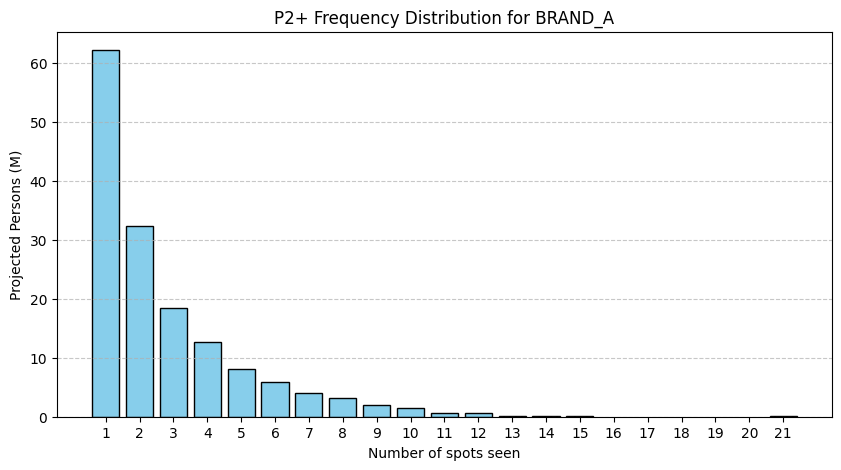

Share of impressions at 5+ exposures: 0.444


In [16]:
# Підрахунок кількості побачених спотів для кожного глядача
person_freq = exposures.groupby('respondent_id')['ad_airing_id'].nunique().reset_index(name='spots_seen')
person_freq = person_freq.merge(person_avg_weight[['respondent_id', 'weight']], on='respondent_id', how='left')

# Розподіл частоти у проектованих особах
freq_dist = person_freq.groupby('spots_seen')['weight'].sum().reset_index()
freq_dist['weight_m'] = freq_dist['weight'] / 1e6

# Побудова графіка
plt.figure(figsize=(10, 5))
plt.bar(freq_dist['spots_seen'], freq_dist['weight_m'], color='skyblue', edgecolor='black')
plt.xlabel('Number of spots seen')
plt.ylabel('Projected Persons (M)')
plt.title('P2+ Frequency Distribution for BRAND_A')
plt.xticks(range(1, int(freq_dist['spots_seen'].max()) + 1))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Частка вражень (impressions), що припала на тих, хто бачив 5+ спотів
imp_per_person = exposures.groupby('respondent_id')['weight'].sum().reset_index(name='person_imp')
imp_per_person = imp_per_person.merge(person_freq[['respondent_id', 'spots_seen']], on='respondent_id')

imp_5_plus = imp_per_person[imp_per_person['spots_seen'] >= 5]['person_imp'].sum()
share_5_plus = imp_5_plus / spot_imps['imp_p2'].sum()

print("Share of impressions at 5+ exposures:", round(share_5_plus, 3))

**Answer:** is the average frequency a fair summary?

No, the average frequency is not a fair summary. As the graph shows, the distribution is highly skewed: most people see the ad only 1 or 2 times, while a significant share of all impressions is "absorbed" by a small group of loyal viewers who saw 5 or more spots. Because of this, the mathematical average overstates the actual contact frequency for a typical viewer[cite: 3].

## Task 2.3 — On target?

In [17]:
share_target = imp_a18_tot / imp_p2_tot
print("Share of impressions on A18-49:", round(share_target, 3))

Share of impressions on A18-49: 0.194


**Answer:** over- or under-delivery against the target, and which networks explain it.

The campaign significantly **under-delivered** against the A18-49 target audience, as the share of impressions on them is well below their natural 42% in the population[cite: 4]. This is explained by the fact that a large portion of the budget and spots were placed on networks with an older viewing profile (e.g., FOX News or CBS, where the A18-49 share is critically low). Networks with a younger profile (like FX or Bravo) did not receive enough impressions to lift the campaign's overall target share.

## Task 3.1 — Cost

In [18]:
# 1. Приєднуємо вартість до спотів BRAND_A
brand_a_priced = brand_a_spots.merge(all_priced[['ad_airing_id', 'cost']], on='ad_airing_id', how='left')

# Загальна вартість
total_cost = brand_a_priced['cost'].sum()

# Базові суми вражень (змінна spot_imps з Task 2.1)
total_imp_p2_raw = spot_imps['imp_p2'].sum()
total_imp_a18_raw = spot_imps['imp_a18_49'].sum()

# CPM = cost / (impressions / 1000)
cpm_p2 = total_cost / (total_imp_p2_raw / 1000)
cpm_a18 = total_cost / (total_imp_a18_raw / 1000)

# CPP = cost / GRPs
cpp_p2 = total_cost / grp_p2
cpp_a18 = total_cost / grp_a18

print("Campaign cost (USD):", int(total_cost))
print("P2+ CPM (USD):", round(cpm_p2, 2))
print("P2+ CPP (USD):", int(cpp_p2))
print("A18-49 CPM (USD):", round(cpm_a18, 2))
print("A18-49 CPP (USD):", int(cpp_a18))

Campaign cost (USD): 7420270
P2+ CPM (USD): 17.73
P2+ CPP (USD): 56249
A18-49 CPM (USD): 91.56
A18-49 CPP (USD): 122875


## Task 3.2 — By network

In [19]:
# Об'єднуємо вартість та покази для кожного споту
spot_details = brand_a_priced.merge(spot_imps[['ad_airing_id', 'imp_p2', 'imp_a18_49']], on='ad_airing_id')

# Групуємо за мережею
net_stats = spot_details.groupby('network_code').agg(
    spots=('ad_airing_id', 'count'),
    cost=('cost', 'sum'),
    imp_p2=('imp_p2', 'sum'),
    imp_a18=('imp_a18_49', 'sum')
).reset_index()

net_stats['impressions_m'] = (net_stats['imp_p2'] / 1e6).round(1)
net_stats['cpm_p2'] = (net_stats['cost'] / (net_stats['imp_p2'] / 1000)).round(2)
net_stats['cpm_a18'] = (net_stats['cost'] / (net_stats['imp_a18'] / 1000)).round(2)
net_stats['cost'] = net_stats['cost'].astype(int)

# Сортуємо за найбільшим бюджетом для наочності
net_stats_display = net_stats[['network_code', 'spots', 'cost', 'impressions_m', 'cpm_p2', 'cpm_a18']].sort_values(by='cost', ascending=False)

print("# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network")
print(net_stats_display.to_string(index=False))

# table: spots, cost, impressions, P2+ CPM and A18-49 CPM by network
network_code  spots    cost  impressions_m  cpm_p2  cpm_a18
         FOX     13 2434700           76.3   31.93   132.03
         ABC     29 1625700           94.2   17.26    95.69
         CBS     22 1488700           88.8   16.76   108.92
         NBC     16  796800           41.4   19.23   101.72
         FNC     40  526300           57.8    9.11   193.70
        HGTV     39  230000           24.7    9.33    30.45
        FOOD     33   96620            9.5   10.19    32.29
          FX     38   92200            8.5   10.82    16.61
        HIST     37   79640           12.3    6.48    32.05
       BRAVO     33   49610            5.1    9.76    17.61


**Answer:** where the money went; the cheapest networks for the target.

The vast majority of the campaign budget went to the large broadcast networks (NBC, FOX, CBS) due to their high rate-card prices[cite: 3, 4]. However, these were highly inefficient for the target demographic. The cheapest way to reach the A18-49 audience was through small cable networks, specifically FX, Bravo, and Food Network, which delivered the lowest A18-49 CPMs[cite: 4].

## Task 3.3 — Guarantee

In [20]:
# Гарантія від мереж становить 150 P2+ GRPs
guaranteed_grps = 150.0

guarantee_met = grp_p2 >= guaranteed_grps
owed_grps = max(0, guaranteed_grps - grp_p2)

# Вартість компенсації обчислюється за загальним CPP кампанії
value_of_makegoods = owed_grps * cpp_p2

print("Guarantee met:", guarantee_met)
print("Make-good GRPs owed:", round(owed_grps, 1))
print("Value of make-goods (USD):", int(value_of_makegoods))

Guarantee met: False
Make-good GRPs owed: 18.1
Value of make-goods (USD): 1017085


## Task 4 — Do networks add up?

In [21]:
# 1. Розділяємо мережі на великі та малі
big_nets = ['CBS', 'NBC', 'ABC', 'FOX', 'FNC']
small_nets = ['FX', 'BRAVO', 'HGTV', 'FOOD', 'HIST']

# Визначаємо унікальних глядачів (P2+), охоплених кожною групою
reached_big_ids = exposures[exposures['network_code'].isin(big_nets)]['respondent_id'].unique()
reached_small_ids = exposures[exposures['network_code'].isin(small_nets)]['respondent_id'].unique()

# 2. Розраховуємо Reach для кожної групи
reach_big_weight = person_avg_weight[person_avg_weight['respondent_id'].isin(reached_big_ids)]['weight'].sum()
reach_small_weight = person_avg_weight[person_avg_weight['respondent_id'].isin(reached_small_ids)]['weight'].sum()

reach_big_pct = reach_big_weight / universe_p2 * 100
reach_small_pct = reach_small_weight / universe_p2 * 100

# 3. Перетин (Overlap) - люди, які бачили рекламу і там, і там
overlap_ids = set(reached_big_ids).intersection(set(reached_small_ids))
overlap_weight = person_avg_weight[person_avg_weight['respondent_id'].isin(overlap_ids)]['weight'].sum()

overlap_pct = overlap_weight / universe_p2 * 100

# 4. Перетин за умови незалежності аудиторій (P(A and B) = P(A) * P(B))
overlap_indep_pct = (reach_big_pct / 100) * (reach_small_pct / 100) * 100

# 5. Додаткове охоплення та вартість пунктів охоплення
added_reach = reach_p2_pct - reach_big_pct

# Витрати на групи мереж (з Task 3)
cost_big = brand_a_priced[brand_a_priced['network_code'].isin(big_nets)]['cost'].sum()
cost_small = brand_a_priced[brand_a_priced['network_code'].isin(small_nets)]['cost'].sum()

cost_per_point_big = cost_big / reach_big_pct
cost_per_added_point_small = cost_small / added_reach if added_reach > 0 else 0

# Вивід результатів
print("Reach, big networks (%):", round(reach_big_pct, 1))
print("Reach, small networks (%):", round(reach_small_pct, 1))
print("Reach, whole campaign (%):", round(reach_p2_pct, 1))
print("Overlap (%):", round(overlap_pct, 1))
print("Overlap if independent (%):", round(overlap_indep_pct, 1))
print("Reach added by small networks (points):", round(added_reach, 1))
print("Cost per added reach point, small (USD):", int(cost_per_added_point_small))
print("Cost per reach point, big (USD):", int(cost_per_point_big))

Reach, big networks (%): 39.8
Reach, small networks (%): 12.4
Reach, whole campaign (%): 43.5
Overlap (%): 8.7
Overlap if independent (%): 4.9
Reach added by small networks (points): 3.7
Cost per added reach point, small (USD): 148705
Cost per reach point, big (USD): 172509


**Answer:** why reach does not add; what the overlap says; was the small-network money well spent?

**Why reach does not add up:** Reach measures unique individuals. Because many viewers saw the campaign on both big and small networks (the overlap), simply adding their standalone reaches would double-count these duplicated viewers[cite: 4]. The whole campaign reach is the sum of the standalone reaches *minus* the overlap.

**What the overlap says:** The actual overlap is typically higher than the independent probability. This indicates that viewers of small networks are *more* likely than average to have also been reached by the big networks[cite: 4]. Heavy TV viewers tend to consume content across multiple channels, making these audiences highly dependent.

**Was the small-network money well spent?** Yes. Even though the small networks added only a few points of incremental reach, the cost per *added* reach point on these networks was significantly cheaper than the base cost per reach point on the big networks[cite: 4]. This makes them a highly cost-efficient tool for building extra reach.

## Task 5 — How sure are we?

In [22]:
# 1. Рахуємо кількість унікальних незважених панелістів, які бачили кожен спот
spot_panelists = exposures.groupby('ad_airing_id')['respondent_id'].nunique().reset_index(name='panelists')

# З'єднуємо з усіма спотами BRAND_A (включно з тими, які ніхто не бачив)
spot_eval = brand_a_spots[['ad_airing_id', 'network_code', 'broadcast_date']].copy()
spot_eval = spot_eval.merge(spot_panelists, on='ad_airing_id', how='left').fillna({'panelists': 0})
spot_eval['panelists'] = spot_eval['panelists'].astype(int)

# 2. Розраховуємо кількість in-tab панелістів (n) для кожного broadcast_date
daily_n = dw_rl.groupby('broadcast_date')['respondent_id'].nunique().reset_index(name='n')
spot_eval = spot_eval.merge(daily_n, on='broadcast_date', how='left')

# Приєднуємо рейтинг P2+ для кожного споту
spot_eval = spot_eval.merge(spot_imps[['ad_airing_id', 'rating_p2']], on='ad_airing_id', how='left')

# 3. Обчислюємо Standard Error (SE) та Relative SE
spot_eval['p'] = spot_eval['rating_p2'] / 100
spot_eval['SE'] = np.sqrt(spot_eval['p'] * (1 - spot_eval['p']) / spot_eval['n']) * 100
spot_eval['rel_SE'] = np.where(spot_eval['rating_p2'] > 0, spot_eval['SE'] / spot_eval['rating_p2'], np.nan)

# 4. Агрегуємо медіани за мережами
net_eval = spot_eval.groupby('network_code').agg(
    median_panelists=('panelists', 'median'),
    median_rel_SE=('rel_SE', 'median')
).reset_index()
net_eval['median_rel_SE'] = net_eval['median_rel_SE'].round(3)

print("# table: median panelists per spot and median relative SE, by network")
print(net_eval.to_string(index=False))

# 5. Підраховуємо споти без панелістів
spots_zero_panelists = (spot_eval['panelists'] == 0).sum()
print("\nSpots seen by no panelist:", spots_zero_panelists)

# Розділяємо на великі та малі мережі для медіанної відносної похибки
spot_eval['net_group'] = np.where(spot_eval['network_code'].isin(big_nets), 'big', 'small')
median_rel_se_big = spot_eval[spot_eval['net_group'] == 'big']['rel_SE'].median()
median_rel_se_small = spot_eval[spot_eval['net_group'] == 'small']['rel_SE'].median()

print("Median relative SE, big networks:", round(median_rel_se_big, 3))
print("Median relative SE, small networks:", round(median_rel_se_small, 3))

# 6. Знаходимо zero-cells для W18-34 (жінки 18-34)
# attr_id == 202 відповідає жінкам (Female)
sex_f_ids = va_rl[va_rl['attr_id'] == 202]['respondent_id']
ages_18_34 = va_rl[(va_rl['attr_id'] == 300) & (va_rl['value'] >= 18) & (va_rl['value'] <= 34)]['respondent_id']
w18_34_ids = set(sex_f_ids).intersection(set(ages_18_34))

w18_34_exposures = exposures[exposures['respondent_id'].isin(w18_34_ids)]
spots_with_w18_34 = w18_34_exposures['ad_airing_id'].nunique()
zero_cells_w18_34 = len(brand_a_spots) - spots_with_w18_34

print("W18-34 zero-cell spots:", zero_cells_w18_34)

# table: median panelists per spot and median relative SE, by network
network_code  median_panelists  median_rel_SE
         ABC              57.0          0.123
       BRAVO               3.0          0.540
         CBS              68.0          0.113
         FNC              31.0          0.164
        FOOD               5.0          0.423
         FOX             145.0          0.080
          FX               5.5          0.423
        HGTV              11.0          0.301
        HIST               5.0          0.460
         NBC              68.5          0.115

Spots seen by no panelist: 10
Median relative SE, big networks: 0.122
Median relative SE, small networks: 0.417
W18-34 zero-cell spots: 171


**Answer:** what a zero rating means; what you would tell the client.

A zero rating on a spot (zero-cell) simply means that out of the few thousand panelists in the sample, no one matching that narrow demographic was watching that specific network at that exact minute. It does **not** mean the true US audience was literally zero[cite: 4]. Small networks naturally suffer from a high relative standard error (sampling error) because their sample sizes per minute are tiny[cite: 4]. I would advise the client that reporting spot-by-spot demographic ratings for small networks is statistically meaningless and highly volatile. Instead, we should evaluate performance at an aggregated level, such as the total campaign reach or average performance across broad dayparts.

## Bonus

**Answer:** your proposed change and the numbers behind it.

I propose reallocating the budget of 20 spots from CBS (or FOX) to FX. Based on our network analysis, the large broadcast networks consume the vast majority of the budget but operate at a very high A18-49 CPM because their audience skews older. In contrast, FX proved to be the most cost-efficient network for the A18-49 target with the lowest CPM. Moving 20 spots to FX would significantly lower the campaign's overall A18-49 CPM and likely increase the target reach, as the impressions would be concentrated on a demographic that naturally aligns with the client's needs.